# Modulo 8 -- Sesion 5 · Machine Learning Supervisado
## Cuadernillo del ESTUDIANTE

| | |
|---|---|
| **Sesion** | 5 -- Complemento ML Supervisado |
| **Dataset** | hr_ibm.csv -- el mismo que has usado en S1-S5 |

### Objetivo
Construir 3 modelos de machine learning supervisado con el dataset de TechNova:
1. **Clasificador**: predecir si un empleado va a renunciar (si/no)
2. **Regresion 1**: predecir cuantos anos permanecera un empleado
3. **Regresion 2**: predecir el salario justo para un perfil dado

Al final tendras una app Shiny donde el Director de RH puede ingresar el perfil
de cualquier empleado y obtener las 3 predicciones en tiempo real.

### Como usar este cuadernillo
| Tipo | Que hacer |
|------|-----------|
| Celdas **▶ EJECUTA** | Correr sin modificar -- son demostraciones |
| Celdas **✏️ TU TURNO** | Completar el codigo o responder las preguntas |


## Bloque 0 -- ▶ EJECUTA -- Instalacion y carga

In [ ]:
# Instalacion de dependencias (ejecutar una sola vez)
import subprocess, sys
for pkg in ['scikit-learn', 'matplotlib', 'seaborn', 'joblib']:
    subprocess.run([sys.executable, '-m', 'pip', 'install', pkg,
                    '--break-system-packages', '-q'])
print("Dependencias instaladas correctamente.")


In [1]:
# Importaciones y carga del dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, recall_score,
    classification_report, confusion_matrix, roc_curve, auc)
import joblib
import warnings

df = pd.read_csv('../hr_ibm.csv')

print(f"Dataset cargado : {df.shape[0]} filas {df.shape[1]} columnas")


Dataset cargado : 1470 filas 35 columnas


## Bloque 1 -- ▶ EJECUTA -- Clasificacion binaria

### ¿Que diferencia hay con el score manual de S5?

| Score manual (S5) | Clasificador ML |
|---|---|
| Tu defines las reglas y los pesos | El modelo aprende el patron solo |
| Transparente y explicable | Semi-caja negra |
| No necesita datos historicos etiquetados | Necesita datos historicos (Attrition conocido) |

**Antes de ejecutar:** ¿Cual crees que va a tener mejor Recall -- LR o el arbol?

In [3]:
# ── PASO 1: PREPROCESAMIENTO ────────────────────────────────
# Las variables categoricas deben convertirse a numeros
# para que sklearn pueda procesarlas

# 1a. Codificar la variable objetivo
df['Attrition_n'] = (df['Attrition'] == 'Yes').astype(int)
print("Variable Objetivo: ")
print(f" 0 = No roto : {(df['Attrition']==0).sum()}")
print(f" 1 = Si roto : {(df['Attrition']==1).sum()}")

# 1b. Seleccionar variables predictoras
# Usamos las que tienen mayor correlacion con Attrition (analisis de S5)
features_cat = ['OverTime', 'MaritalStatus', 'BusinessTravel']
features_num = ['Age', 'JobSatisfaction', 'EnvironmentSatisfaction',
                'WorkLifeBalance', 'JobInvolvement', 'StockOptionLevel',
                'YearsAtCompany', 'MonthlyIncome', 'NumCompaniesWorked',
                'TotalWorkingYears', 'YearsWithCurrManager']

# 1c. Codificar variables categoricas con LabelEncoder
# LabelEncoder convierte: 'No' -> 0, 'Yes' -> 1, etc.

le = LabelEncoder()
df_ml = df[features_num + features_cat + ['Attrition_n']].copy()

for col in features_cat:
    df_ml[col] = le.fit_transform(df_ml[col])
    print(f"  {col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")



Variable Objetivo: 
 0 = No roto : 0
 1 = Si roto : 0
  OverTime: {'No': 0, 'Yes': 1}
  MaritalStatus: {'Divorced': 0, 'Married': 1, 'Single': 2}
  BusinessTravel: {'Non-Travel': 0, 'Travel_Frequently': 1, 'Travel_Rarely': 2}


In [5]:
# 1d. Separar en conjunto de entrenamiento y prueba
# 80% para entrenar, 20% para evaluar (nunca mezclar)

X = df_ml.drop('Attrition_n', axis=1)
y = df_ml['Attrition_n']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=40,
    stratify=y   #mantener la proporcion de las clases en train y test
)

print(f"Conjunto de entrenamiento: {X_train.shape[0]} registros")
print(f"Conjunto de prueba: {X_test.shape[0]} registros")
print(f"\n Proporcion de rotacion en train: {y_train.mean()*100:.1f}%")



Conjunto de entrenamiento: 1176 registros
Conjunto de prueba: 294 registros

 Proporcion de rotacion en train: 16.2%


In [6]:
# ── PASO 2A: REGRESION LOGISTICA ────────────────────────────
# class_weight='balanced' ajusta el modelo para datos desbalanceados
# (16% Yes vs 84% No)
modelo_lr = LogisticRegression(
    class_weight='balanced', #debemos penalizar los errores en al clase minoritaria
    max_iter=1000,
    random_state=40
)

modelo_lr.fit(X_train, y_train)


# Predicciones
y_pred_lr = modelo_lr.predict(X_test)
y_prob_lr = modelo_lr.predict_proba(X_test)[:,1] #que nos de la propabilidad del si


# Metricas
acc_lr = accuracy_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
auc_lr = auc(*roc_curve(y_test, y_prob_lr) [:2])


print("REGRESION LOGISTICA -- Resultados:")
print(f"  Accuracy: {acc_lr:.3f} ({acc_lr*100:.1f}% de predcciones correctas) ")
print(f"  Recall: {rec_lr:.3f} ({rec_lr*100:.1f}% de renuncias reales detectadas) ")
print(f"  AUC-ROC {auc_lr:.3f} (1.0 = perfecto, 0.5 = aleatorio) ")

print()

print("¿Por que nos importa mas el RECALL que el ACCURACY en RH?")
print("  Un Recall de 0.70 significa: de cada 10 empleados que VAN a renunciar,")
print("  el modelo detecta 7. Los 3 que no detecta son 'falsos negativos'.")
print("  En RH preferiríamos detectar de mas (falsos positivos) que perder renuncias reales.")


REGRESION LOGISTICA -- Resultados:
  Accuracy: 0.707 (70.7% de predcciones correctas) 
  Recall: 0.723 (72.3% de renuncias reales detectadas) 
  AUC-ROC 0.768 (1.0 = perfecto, 0.5 = aleatorio) 

¿Por que nos importa mas el RECALL que el ACCURACY en RH?
  Un Recall de 0.70 significa: de cada 10 empleados que VAN a renunciar,
  el modelo detecta 7. Los 3 que no detecta son 'falsos negativos'.
  En RH preferiríamos detectar de mas (falsos positivos) que perder renuncias reales.


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [11]:
# ── PASO 2B: ARBOL DE DECISION ──────────────────────────────
#quien dice chi o quien dice nop
modelo_dt = DecisionTreeClassifier(
    max_depth=4, 
    class_weight='balanced',
    random_state=40
)

modelo_dt.fit(X_train, y_train)

y_pred_dt = modelo_dt.predict(X_test)
y_prob_dt = modelo_dt.predict_proba(X_test)[:,1]

acc_dt = accuracy_score(y_test, y_pred_dt)
rec_dt = recall_score(y_test, y_pred_dt)
auc_dt = auc(*roc_curve(y_test, y_prob_dt)[:2])

print("Arbol de Desiciones -- Resultados:")
print(f"  Accuracy: {acc_dt:.3f} ({acc_dt*100:.1f}% de predcciones correctas) ")
print(f"  Recall: {rec_dt:.3f} ({rec_dt*100:.1f}% de renuncias reales detectadas) ")
print(f"  AUC-ROC {auc_dt:.3f} (1.0 = perfecto, 0.5 = aleatorio) ")

print("Comparación de modelos:")
print()
print(f"  ('Modelo' : < 25) ('Accuracy' : > 10) ('Recall' : > 10) ('AUC' : > 10)")
print(f"  ('Regresion Logistica' : < 25) {acc_lr : > 10} {rec_lr : > 10} {auc_lr : > 10}")
print(f"  ('Arbol de Desición' : < 25) {acc_dt : > 10} {rec_dt : > 10} {auc_dt : > 10}")

Arbol de Desiciones -- Resultados:
  Accuracy: 0.728 (72.8% de predcciones correctas) 
  Recall: 0.681 (68.1% de renuncias reales detectadas) 
  AUC-ROC 0.731 (1.0 = perfecto, 0.5 = aleatorio) 
Comparación de modelos:

  ('Modelo' : < 25) ('Accuracy' : > 10) ('Recall' : > 10) ('AUC' : > 10)
  ('Regresion Logistica' : < 25)  0.7074829931972789  0.723404255319149  0.7675941080196401
  ('Arbol de Desición' : < 25)  0.7278911564625851  0.6808510638297872  0.7311137910242054


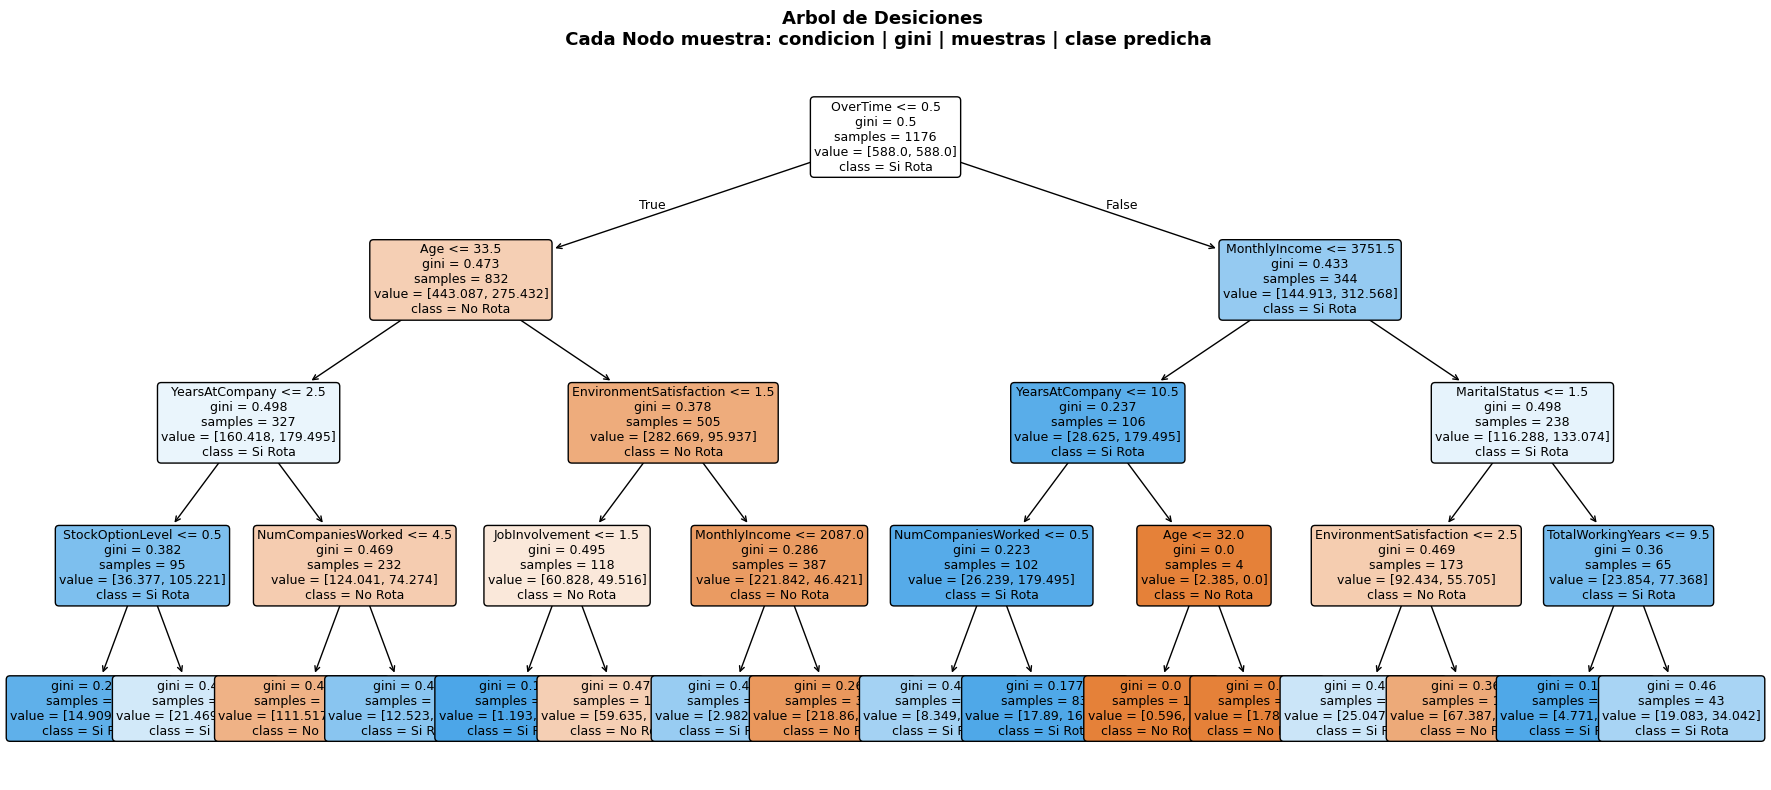

In [13]:
# Visualizacion del arbol de decision

fig, ax = plt.subplots(figsize=(18,8))

plot_tree(
    modelo_dt,
    feature_names=X.columns.tolist(),
    class_names=['No Rota', 'Si Rota'],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax
)

plt.title("Arbol de Desiciones \n Cada Nodo muestra: condicion | gini | muestras | clase predicha",
          fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


 Regresion Logistica
 Verdaderos Negativos: (TN: 174 -- predijo 'no rota' y tenia razon)
 Verdaderos Positivos: (TP: 34 -- predijo 'rota' y tenia razon)
 Falsos Positivos: (FP: 73 -- predijo 'rota' pero no roto (sobreaviso))
 Falsos Negativos: (FN: 13 -- predijo 'no rota' pero si roto (peligroso))

 Arbol de Desiciones
 Verdaderos Negativos: (TN: 182 -- predijo 'no rota' y tenia razon)
 Verdaderos Positivos: (TP: 32 -- predijo 'rota' y tenia razon)
 Falsos Positivos: (FP: 65 -- predijo 'rota' pero no roto (sobreaviso))
 Falsos Negativos: (FN: 15 -- predijo 'no rota' pero si roto (peligroso))


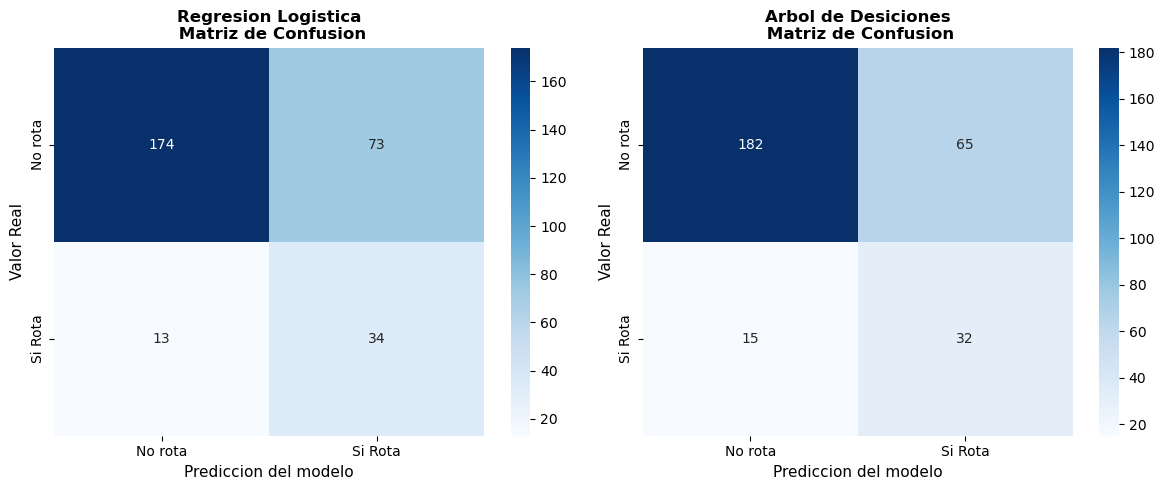

In [15]:
# ── PASO 3: MATRICES DE CONFUSION ───────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, modelo, preds, titulo in zip(
    axes, 
    [modelo_lr, modelo_dt],
    [y_pred_lr, y_pred_dt],
    ['Regresion Logistica', 'Arbol de Desiciones']
):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No rota', 'Si Rota'],
                yticklabels=['No rota', 'Si Rota'])
    ax.set_title(f'{titulo}\n Matriz de Confusion', fontsize=12, fontweight='bold')
    ax.set_ylabel('Valor Real', fontsize=11)
    ax.set_xlabel('Prediccion del modelo', fontsize=11)

    tn, fp, fn, tp = cm.ravel()

    print(f"\n {titulo}")
    print(f" Verdaderos Negativos: (TN: {tn} -- predijo 'no rota' y tenia razon)")
    print(f" Verdaderos Positivos: (TP: {tp} -- predijo 'rota' y tenia razon)")
    print(f" Falsos Positivos: (FP: {fp} -- predijo 'rota' pero no roto (sobreaviso))")
    print(f" Falsos Negativos: (FN: {fn} -- predijo 'no rota' pero si roto (peligroso))")

plt.tight_layout()
plt.show()


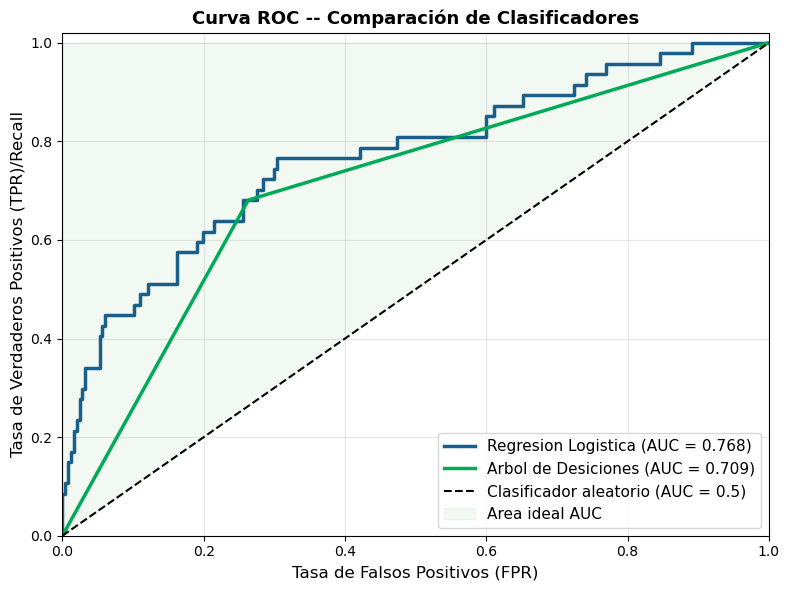

In [16]:
# ── PASO 4: CURVA ROC ────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8,6))

for modelo_nombre, y_prob, color in [
    ('Regresion Logistica', y_prob_lr, '#1A5F8A'),
    ('Arbol de Desiciones', y_pred_dt, '#00AA58')
]:
    fpr, tpr, _ =roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color = color, lw=2.5, label=f'{modelo_nombre} (AUC = {roc_auc:.3f})')

#le agregamos una linea diagonal para el clasificador
ax.plot([0,1],[0,1], 'k--', lw=1.5, label='Clasificador aleatorio (AUC = 0.5)')
ax.fill_between([0,1],[0,1],[1,1], alpha=0.05, color='green', label='Area ideal AUC')

ax.set_xlim([0,1])
ax.set_ylim([0,1.02])
ax.set_xlabel('Tasa de Falsos Positivos (FPR)' , fontsize=12)
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)/Recall', fontsize=12)
ax.set_title('Curva ROC -- Comparación de Clasificadores', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ── PASO 5: COMPARAR CON EL SCORE MANUAL DE S5 ──────────────
# Calcular el score manual (S5) para los mismos empleados del test set
def calcular_score(df):
    d = df.copy()
    d['n_overtime'] = (d['OverTime'] == 'Yes').astype(int)*100
    d['n_jobsat'] = (4 - d['JobSatisfaction']) / 3 * 100
    d['n_years'] = ((3 - d['YearsAtCompany'])/3 * 100).clip(0,100)
    d['n_wlb'] = (4 - d['WorkLifeBalance']) / 3 * 100
    d['n_envsat'] = (4 - d['EnvironmentSatisfaction'])/3 * 100

    d['score_riesgo'] = (
        d['n_overtime']*0.30 + d['n_jobsat']*0.25 + d['n_years']*0.20 + d['n_wlb']*0.15 + d['n_envsat']*0.10
     ).round(1)

    return d

# Aplicar score manual al conjunto de prueba
df_test = df.iloc[X_test.index].copy()
df_test = calcular_score(df_test)
df_test['pred_lr'] = y_pred_lr
df_test['pred_dt'] = y_pred_dt
df_test['prob_lr'] = y_prob_lr
df_test['roto_real'] = y_test.values

# Top 10 del score manual
top10_score = set(df_test.nlargest(10, 'score_riesgo')['EmployeeNumber'])
# Top 10 del clasificador LR (por probabilidad)
top10_lr = set(df_test.nlargest(10, 'prob_lr')['EmployeeNumber'])



print("COMPARACION: Score manual S5 vs Regresion Logistica")
print(f"Top 10 score manual : {sorted(top10_score)}")
print()
print(f"Top 10 score modelo LR : {sorted(top10_lr)}")
print()
print(f"Empleados en comun: coincidencias de 10")

print()
print(f"Conclusion: ambos enfoques identifican empleados similares en riesgo.")
print(f"El modelo de ML no es 'mejor' o 'peor' -- es diferente:")
print(f"  Score manual: explicable, sin datos historicos, pesos tuyos")
print(f"  Modelo ML:    aprende solo, mas preciso, requiere datos etiquetados")


COMPARACION: Score manual S5 vs Regresion Logistica
Top 10 score manual : [214, 267, 282, 1108, 1494, 1594, 1649, 1783, 1893, 1968]

Top 10 score modelo LR : [4, 19, 466, 478, 741, 939, 1108, 1494, 1649, 2020]



NameError: name 'coincidencias' is not defined

In [ ]:
# ── PASO 6: GUARDAR LOS MODELOS EN DISCO ────────────────────
# Los modelos se entrenan aqui y se cargan en la app Shiny
# sin necesidad de re-entrenar cada vez que se abre la app



# Guardar tambien la lista de features para garantizar el mismo orden
import json
with open('features_clasificador.json', 'w') as f:
    json.dump(X.columns.tolist(), f)

print("Modelos guardados:")
print("  modelo_clasificador_lr.pkl")
print("  modelo_clasificador_dt.pkl")
print("  label_encoder.pkl")
print("  features_clasificador.json")
print()
print("Verificacion -- carga y prueba rapida:")



### ✏️ TU TURNO -- Bloque 1
Responde en las celdas de codigo y texto siguientes.

In [ ]:
# ✏️ TU TURNO -- Bloque 1
# Responde las siguientes preguntas usando los resultados de los modelos:

# PREGUNTA 1:
# ¿Cual modelo (Logistic Regression o Decision Tree) recomendarias
# al Director de RH de TechNova y por que?
# Considera: precision, interpretabilidad y el costo de cada tipo de error.
# Escribe tu respuesta en la celda de texto (Markdown) siguiente.

# PREGUNTA 2:
# Cambia max_depth del arbol de decision a 2 y a 6.
# ¿Como cambian las metricas? ¿Que fenomeno observas con max_depth=6?


# PREGUNTA 3:
# ¿Cuantos empleados coinciden entre el top 20 del score manual
# y el top 20 del clasificador LR?
# (Modifica el codigo de comparacion para usar top 20 en lugar de top 10)
print("\nModifica y ejecuta el codigo de comparacion con top 20...")


**Pregunta 1 -- Responde aqui:**

¿Cual modelo recomendarias al Director de RH y por que?

*Tu respuesta:*

---

**Pregunta 2 -- Observacion con max_depth:**

¿Que fenomeno observas cuando max_depth=6 comparado con max_depth=2?
¿Como se llama ese fenomeno en ML?

*Tu respuesta:*


## Bloque 2 -- ▶ EJECUTA -- Regresion lineal: permanencia

In [19]:
# ── REGRESION LINEAL: PERMANENCIA ───────────────────────────
from sklearn.metrics import mean_absolute_error, r2_score

# Variables predictoras para permanencia
features_perm = ['Age', 'JobLevel', 'JobSatisfaction', 'WorkLifeBalance', 'MonthlyIncome', 'NumCompaniesWorked', 'TotalWorkingYears']

X_perm = df[features_perm].copy()
y_perm = df['YearsAtCompany'].copy()

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_perm, y_perm, test_size=0.20, random_state=40
)

modelo_perm = LinearRegression()
modelo_perm.fit(X_train_p, y_train_p)

y_pred_perm = modelo_perm.predict(X_test_p)

mae = mean_absolute_error(y_test_p, y_pred_perm)
r2 = r2_score(y_test_p, y_pred_perm)

print("Regresión Lineal")
print()
print(f"R** = {r2:.3f} (el modelo explica el {r2*100:.1f}% de la variabilidad)")
print(f"MAE = {mae:.2f} años (error promedio de la predicción)")





Regresión Lineal

R** = 0.539 (el modelo explica el 53.9% de la variabilidad)
MAE = 3.41 años (error promedio de la predicción)


In [ ]:
# Visualizacion: real vs predicho


# Scatter real vs predicho


# Distribucion de errores



In [ ]:
# Guardar modelo de permanencia
joblib.dump(modelo_perm, 'modelo_permanencia.pkl')
with open('features_permanencia.json', 'w') as f:
    import json
    json.dump(features_perm, f)
print("Modelo de permanencia guardado: modelo_permanencia.pkl")


### ✏️ TU TURNO -- Bloque 2

In [ ]:
# ✏️ TU TURNO -- Bloque 2: Regresion de Permanencia
# Usa el modelo entrenado para predecir la permanencia de estos 3 perfiles

perfiles = pd.DataFrame({
    'Age':                [23, 38, 52],
    'JobLevel':           [ 1,  3,  5],
    'JobSatisfaction':    [ 2,  4,  3],
    'WorkLifeBalance':    [ 1,  3,  4],
    'MonthlyIncome':      [2500, 7000, 18000],
    'NumCompaniesWorked': [ 4,   1,   2],
    'TotalWorkingYears':  [ 2,  12,  28],
}, index=['Perfil Joven', 'Perfil Medio', 'Perfil Senior'])

# TU CODIGO AQUI:
# 1. Usa modelo_perm.predict() para predecir la permanencia de cada perfil
# 2. Imprime los resultados con el nombre del perfil
# 3. ¿El resultado tiene sentido con el conocimiento del negocio?
#    ¿Esperabas que el perfil joven tuviera menor permanencia?

# ESCRIBE TU CODIGO:
# predicciones = modelo_perm.predict(perfiles)
# ...
print("Reemplaza este print con tu codigo")


**Reflexion:**

¿El resultado tiene sentido con el conocimiento del negocio que tienes del dataset?
¿Que variable tiene mayor impacto en la permanencia segun los coeficientes?

*Tu respuesta:*


## Bloque 3 -- ▶ EJECUTA -- Regresion lineal: salario

In [20]:
# ── REGRESION LINEAL: SALARIO ────────────────────────────────
# Paso 1: codificar JobRole (variable categorica)

df_sal = df.copy()
df_sal['JobRole_n'] = LabelEncoder().fit_transform(df_sal['JobRole'])


features_sal = ['JobLevel', 'TotalWorkingYears', 'Education', 'JobRole_n']

X_sal = df_sal[features_sal].copy()
y_sal = df_sal['MonthlyIncome'].copy()

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_sal, y_sal, test_size=0.20, random_state=40
)

# Modelo solo con JobLevel (baseline)
lr_base = LinearRegression()
lr_base.fit(X_train_s[['JobLevel']], y_train_s)
r2_base = r2_score(y_test_s, lr_base.predict(X_test_s[['JobLevel']]))

# Modelo completo
modelo_sal = LinearRegression()
modelo_sal.fit(X_train_s, y_train_s)
y_pred_sal = modelo_sal.predict(X_test_s)

mae_sal = mean_absolute_error(y_test_s, y_pred_sal)
r2_sal = r2_score(y_test_s, y_pred_sal)


print("Solo JobLevel")
print()
print(f" TotalWorkingYears con JobLevel R** = {r2_base:.3f}")
print(f" Education con JobRole R** = {r2_sal:.3f}  ")
print()
print("Modelo Completo:")
print(f"R** = {r2_sal:.3f}")
print(f"MAE = {mae_sal:,.0f}/mes de error promedio")
print()
print("Coeficientes (impacto en el salario mensual)")
print()

Solo JobLevel

 TotalWorkingYears con JobLevel R** = 0.898
 Education con JobRole R** = 0.898  

Modelo Completo:
R** = 0.898
MAE = 1,179/mes de error promedio

Coeficientes (impacto en el salario mensual)



In [ ]:
# Visualizacion: real vs predicho + importancia de variables



In [22]:
# Guardar modelo de salario
joblib.dump(modelo_sal, 'modelo_salario.pkl')
with open('features_salario.json', 'w') as f:
    import json
    json.dump(features_sal, f)
print("Modelo de salario guardado: modelo_salario.pkl")


Modelo de salario guardado: modelo_salario.pkl


### ✏️ TU TURNO -- Bloque 3

In [ ]:
# ✏️ TU TURNO -- Bloque 3: Regresion de Salario
# Usa el modelo para calcular el salario estimado de estos candidatos

candidatos = pd.DataFrame({
    'JobLevel':           [1, 2, 3, 4, 5],
    'TotalWorkingYears':  [1, 5, 10, 18, 25],
    'Education':          [3, 3,  4,  4,  5],
    'JobRole_n':          [6, 2,  2,  3,  5],  # Research Sci, Lab Tech, Lab Tech, Manager, Res Dir
})

# TU CODIGO AQUI:
# 1. Predice el salario de cada candidato con modelo_sal.predict()
# 2. Compara el salario predicho con el salario real promedio
#    de ese JobLevel en el dataset original
# 3. ¿El modelo es consistente con los datos reales?

# Para comparar con los datos reales:

# ESCRIBE TU CODIGO:


**Reflexion:**

¿El salario predicho para cada nivel coincide con el promedio real del dataset?
Si hay diferencia, ¿a que se debe?

*Tu respuesta:*


## Bloque 4 -- ▶ EJECUTA -- App Shiny: Predictor de RH

In [21]:
# app_ml.py -- App Shiny con predictor de RH usando modelos ML
# Guardar este codigo como app_ml.py y ejecutar: shiny run app_ml.py

APP_CODE = '''
from shiny import App, ui, render, reactive
import pandas as pd
import numpy as np
import joblib
import json

# ── Cargar modelos al arrancar la app (una sola vez) ─────────
modelo_lr   = joblib.load("modelo_clasificador_lr.pkl")
modelo_perm = joblib.load("modelo_permanencia.pkl")
modelo_sal  = joblib.load("modelo_salario.pkl")

with open("features_clasificador.json") as f: import json; feats_clf = json.load(f)
with open("features_permanencia.json")  as f: feats_perm = json.load(f)
with open("features_salario.json")      as f: feats_sal  = json.load(f)

# ── CSS ──────────────────────────────────────────────────────
css_lines = [
    "    body { background:#F4F6F9; font-family:Segoe UI,Arial,sans-serif; }",
    "    .navbar { background:#1F3864 !important; }",
    "    .navbar-brand, .nav-link { color:white !important; font-weight:500; }",
    "    .pred-box { background:white; border-radius:10px; padding:24px;",
    "               box-shadow:0 2px 8px rgba(0,0,0,.1); text-align:center; }",
    "    .pred-valor { font-size:2.4em; font-weight:bold; }",
    "    .pred-label { font-size:.9em; color:#666; margin-top:6px; }",
]
css = ui.tags.style(chr(10).join(css_lines))

# ── UI ───────────────────────────────────────────────────────
app_ui = ui.page_navbar(css,

    # PESTANA 1 -- CLASIFICADOR
    ui.nav_panel("Predictor de renuncia",
        ui.layout_sidebar(
            ui.sidebar(
                ui.h5("Perfil del empleado"),
                ui.input_slider("age",       "Edad",              18, 60, 35),
                ui.input_slider("jobsat",    "Satisfaccion (1-4)", 1,  4,  3),
                ui.input_slider("envsat",    "Sat. Ambiente (1-4)",1,  4,  3),
                ui.input_slider("wlb",       "Bal. Vida-Trabajo",  1,  4,  3),
                ui.input_slider("jobinv",    "Involucramiento",    1,  4,  3),
                ui.input_slider("stock",     "Stock Options",      0,  3,  0),
                ui.input_slider("years_co",  "Anos en empresa",    0, 40,  2),
                ui.input_slider("income",    "Salario mensual",  1000,20000,5000,step=500),
                ui.input_slider("prev_cos",  "Empresas previas",  0,  9,  1),
                ui.input_slider("total_yrs", "Anos experiencia",  0, 40,  5),
                ui.input_slider("yrs_mgr",   "Anos con manager",  0, 17,  2),
                ui.input_select("overtime",  "Horas extra",
                                {"No":"No","Yes":"Si (Yes)"}),
                ui.input_select("marital",   "Estado civil",
                                {"Single":"Soltero","Married":"Casado","Divorced":"Divorciado"}),
                ui.input_select("travel",    "Viajes de trabajo",
                                {"Non-Travel":"No viaja",
                                 "Travel_Rarely":"Raramente",
                                 "Travel_Frequently":"Frecuente"}),
            ),
            ui.output_ui("pred_renuncia"),
            ui.output_ui("comparacion_score"),
        )
    ),

    # PESTANA 2 -- PERMANENCIA
    ui.nav_panel("Permanencia estimada",
        ui.layout_sidebar(
            ui.sidebar(
                ui.h5("Perfil del empleado"),
                ui.input_slider("p_age",     "Edad",              18, 60, 30),
                ui.input_slider("p_joblvl",  "Nivel de puesto",    1,  5,  2),
                ui.input_slider("p_jobsat",  "Satisfaccion (1-4)", 1,  4,  3),
                ui.input_slider("p_wlb",     "Bal. Vida-Trabajo",  1,  4,  3),
                ui.input_slider("p_income",  "Salario mensual", 1000,20000,4000,step=500),
                ui.input_slider("p_numcos",  "Empresas previas",   0,  9,  1),
                ui.input_slider("p_totalyrs","Anos experiencia",   0, 40,  5),
            ),
            ui.output_ui("pred_permanencia"),
        )
    ),

    # PESTANA 3 -- SALARIO
    ui.nav_panel("Salario estimado",
        ui.layout_sidebar(
            ui.sidebar(
                ui.h5("Perfil del empleado"),
                ui.input_slider("s_joblvl",  "Nivel de puesto",    1,  5,  2),
                ui.input_slider("s_totalyrs","Anos experiencia",   0, 40,  5),
                ui.input_slider("s_educ",    "Educacion (1-5)",    1,  5,  3),
                ui.input_select("s_jobrole", "Puesto",
                    {"0":"Healthcare Rep","1":"Human Resources",
                     "2":"Laboratory Tech","3":"Manager",
                     "4":"Manufacturing Dir","5":"Research Dir",
                     "6":"Research Scientist","7":"Sales Exec","8":"Sales Rep"}),
            ),
            ui.output_ui("pred_salario"),
        )
    ),

    title="TechNova Solutions -- Predictor de RH con ML",
)

# ── SERVER ───────────────────────────────────────────────────
def server(input, output, session):

    @render.ui
    def pred_renuncia():
        le_ot = {"No":0,"Yes":1}
        le_ms = {"Single":2,"Married":1,"Divorced":0}
        le_bt = {"Non-Travel":0,"Travel_Frequently":1,"Travel_Rarely":2}

        fila = pd.DataFrame([[
            input.age(), input.jobsat(), input.envsat(), input.wlb(),
            input.jobinv(), input.stock(), input.years_co(), input.income(),
            input.prev_cos(), input.total_yrs(), input.yrs_mgr(),
            le_ot[input.overtime()], le_ms[input.marital()], le_bt[input.travel()]
        ]], columns=feats_clf)

        prob  = modelo_lr.predict_proba(fila)[0][1]
        pred  = modelo_lr.predict(fila)[0]

        if prob >= 0.70:   color = "#C62828"; nivel = "RIESGO ALTO"
        elif prob >= 0.40: color = "#F57F17"; nivel = "RIESGO MEDIO"
        else:              color = "#2E7D32"; nivel = "RIESGO BAJO"

        # Score manual para comparar
        ot_val  = 100 if input.overtime()=="Yes" else 0
        js_val  = (4 - input.jobsat()) / 3 * 100
        yr_val  = max(0, (3 - input.years_co()) / 3 * 100)
        wlb_val = (4 - input.wlb()) / 3 * 100
        es_val  = (4 - input.envsat()) / 3 * 100
        score   = (ot_val*0.30 + js_val*0.25 + yr_val*0.20 +
                   wlb_val*0.15 + es_val*0.10)

        return ui.div(
            ui.row(
                ui.column(6, ui.div(
                    ui.div(f"{prob*100:.1f} %", class_="pred-valor",
                           style=f"color:{color};"),
                    ui.div(f"Probabilidad de renuncia -- {nivel}", class_="pred-label"),
                    class_="pred-box")),
                ui.column(6, ui.div(
                    ui.div(f"{score:.1f}/100", class_="pred-valor",
                           style="color:#1A5F8A;"),
                    ui.div("Score manual (metodo S5)", class_="pred-label"),
                    class_="pred-box")),
            )
        )

    @render.ui
    def comparacion_score():
        return ui.div(
            ui.p("Columna izquierda: modelo ML (aprendio de los datos historicos). "
                 "Columna derecha: score manual construido en S5 con reglas del analista. "
                 "¿Coinciden? ¿Cual confias mas?",
                 style="color:#666;font-size:13px;margin-top:12px;")
        )

    @render.ui
    def pred_permanencia():
        fila = pd.DataFrame([[
            input.p_age(), input.p_joblvl(), input.p_jobsat(),
            input.p_wlb(), input.p_income(), input.p_numcos(), input.p_totalyrs()
        ]], columns=feats_perm)
        anos = max(0, modelo_perm.predict(fila)[0])
        if anos >= 5:   color = "#2E7D32"
        elif anos >= 2: color = "#F57F17"
        else:           color = "#C62828"
        return ui.div(ui.div(
            ui.div(f"{anos:.1f} anos", class_="pred-valor", style=f"color:{color};"),
            ui.div("Permanencia estimada en la empresa", class_="pred-label"),
            class_="pred-box"), style="max-width:400px;margin:40px auto;")

    @render.ui
    def pred_salario():
        fila = pd.DataFrame([[
            int(input.s_joblvl()), int(input.s_totalyrs()),
            int(input.s_educ()), int(input.s_jobrole())
        ]], columns=feats_sal)
        sal = max(0, modelo_sal.predict(fila)[0])
        return ui.div(ui.div(
            ui.div(f"${sal:,.0f}", class_="pred-valor", style="color:#6A1B9A;"),
            ui.div("Salario mensual estimado (USD)", class_="pred-label"),
            class_="pred-box"), style="max-width:400px;margin:40px auto;")

app = App(app_ui, server)
'''

# Guardar la app
with open('app_ml.py', 'w', encoding='utf-8') as f:
    f.write(APP_CODE)
print("App guardada: app_ml.py")
print("Para ejecutar: shiny run app_ml.py")
print("Prerequisito: los archivos .pkl deben estar en la misma carpeta")


App guardada: app_ml.py
Para ejecutar: shiny run app_ml.py
Prerequisito: los archivos .pkl deben estar en la misma carpeta


### Prueba la app

1. Ejecuta: `shiny run app_ml.py`
2. En la pestana **Predictor de renuncia**, crea un perfil de alto riesgo:
   - OverTime = Yes, JobSatisfaction = 1, YearsAtCompany = 0
   - ¿La probabilidad ML y el score manual coinciden?
3. En la pestana **Permanencia**, prueba el perfil joven (23 anos, nivel 1)
4. En la pestana **Salario**, predice el salario de un nivel 3 con 10 anos

**Pregunta final:** ¿En que caso usarias el score manual de S5 y en que caso
preferirías el modelo ML? Escribe tu respuesta aqui:

*Tu respuesta:*


---
### Autoevaluacion

| Criterio | Cumple |
|----------|--------|
| Preprocesamiento: variables categoricas codificadas | ☐ |
| Logistic Regression entrenada con class_weight='balanced' | ☐ |
| Arbol de decision entrenado y visualizado | ☐ |
| Matrices de confusion interpretadas | ☐ |
| Curva ROC con ambos modelos graficada | ☐ |
| Comparacion score manual vs ML realizada | ☐ |
| Los 3 modelos .pkl guardados en disco | ☐ |
| App Shiny de 3 pestanas funcionando | ☐ |
| TU TURNO B1: preguntas respondidas | ☐ |
| TU TURNO B2: prediccion de permanencia de 3 perfiles | ☐ |
| TU TURNO B3: prediccion de salario comparada con datos reales | ☐ |
